In [9]:
import torch
print(torch.__version__)


2.15.0+cpu


In [10]:
words = open('names.txt', 'r').read().splitlines()
print(len(words))
print(words[:8])

32033
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']


In [11]:
chars = sorted(set(''.join(words)))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
print(itos)
print(len(itos))

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [12]:
name = words[0]
print(name)
print([stoi[c] for c in name])

emma
[5, 13, 13, 1]


In [13]:
name = words[0]
print(name)
print([stoi[c] for c in name])

emma
[5, 13, 13, 1]


In [14]:
for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        print(ch1, ch2)

. e
e m
m m
m a
a .


In [15]:
xs, ys = [], []

for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
print(xs)
print(ys)

tensor([ 0,  5, 13, 13,  1])
tensor([ 5, 13, 13,  1,  0])


In [16]:
xs, ys = [], []

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        xs.append(stoi[ch1])
        ys.append(stoi[ch2])

xs = torch.tensor(xs)
ys = torch.tensor(ys)

print(xs.shape, ys.shape)
print(xs[:5])
print(ys[:5])

torch.Size([228146]) torch.Size([228146])
tensor([ 0,  5, 13, 13,  1])
tensor([ 5, 13, 13,  1,  0])


In [17]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)

emb = C[xs]

print(C.shape)
print(emb.shape)
print(C[5])
print(emb[1])

torch.Size([27, 10])
torch.Size([228146, 10])
tensor([ 0.1156,  0.8032,  0.5411, -1.1646,  0.1476, -1.0006,  0.3801,  0.4733,
        -0.9103, -0.7830])
tensor([ 0.1156,  0.8032,  0.5411, -1.1646,  0.1476, -1.0006,  0.3801,  0.4733,
        -0.9103, -0.7830])


In [18]:
import torch.nn.functional as F

W1 = torch.randn((10, 100), generator=g) * 0.1
b1 = torch.zeros(100)
W2 = torch.randn((100, 27), generator=g) * 0.01
b2 = torch.zeros(27)

h = torch.tanh(emb @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, ys)

print(h.shape)
print(logits.shape)
print(loss.item())

torch.Size([228146, 100])
torch.Size([228146, 27])
3.2985739707946777


In [19]:
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True
print(sum(p.nelement() for p in parameters))

4097


In [20]:
lossi = []

for i in range(20000):
    ix = torch.randint(0, xs.shape[0], (32,), generator=g)

    emb = C[xs[ix]]
    h = torch.tanh(emb @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, ys[ix])

    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.1 if i < 10000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    lossi.append(loss.item())

print(loss.item())

2.4423937797546387


In [21]:
emb = C[xs]
h = torch.tanh(emb @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, ys)
print(loss.item())

2.4718587398529053


Matplotlib is building the font cache; this may take a moment.


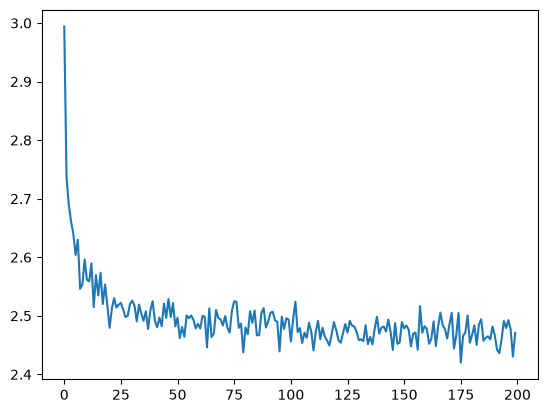

In [22]:
import matplotlib.pyplot as plt
plt.plot(torch.tensor(lossi).view(-1, 100).mean(1))
plt.show()

In [23]:
g2 = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    ix = 0
    while True:
        emb = C[torch.tensor([ix])]
        h = torch.tanh(emb @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g2).item()
        if ix == 0:
            break
        out.append(itos[ix])
    print(''.join(out))

careah
ami
hlel
kimri
reety
skan
s
e
rahnen
deliyrt
kaqhi
nelenia
chaiivin
le
gyd
bm
jori
qsinn
s
lilea


In [24]:
import random

block_size = 3

def build_dataset(words):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    return torch.tensor(X), torch.tensor(Y)

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])
print(Xtr.shape, Xdev.shape, Xte.shape)

torch.Size([182625, 3]) torch.Size([22655, 3]) torch.Size([22866, 3])


In [25]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((block_size * 10, 200), generator=g) * 0.1
b1 = torch.zeros(200)
W2 = torch.randn((200, 27), generator=g) * 0.01
b2 = torch.zeros(27)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True
print(sum(p.nelement() for p in parameters))

11897


In [26]:
lossi = []

for i in range(50000):
    ix = torch.randint(0, Xtr.shape[0], (32,), generator=g)

    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, block_size * 10) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.1 if i < 25000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    lossi.append(loss.item())

print(loss.item())

2.292940616607666


In [27]:
@torch.no_grad()
def split_loss(X, Y):
    emb = C[X]
    h = torch.tanh(emb.view(-1, block_size * 10) @ W1 + b1)
    logits = h @ W2 + b2
    return F.cross_entropy(logits, Y).item()

print('train', split_loss(Xtr, Ytr))
print('dev', split_loss(Xdev, Ydev))

train 2.126598834991455
dev 2.152499198913574


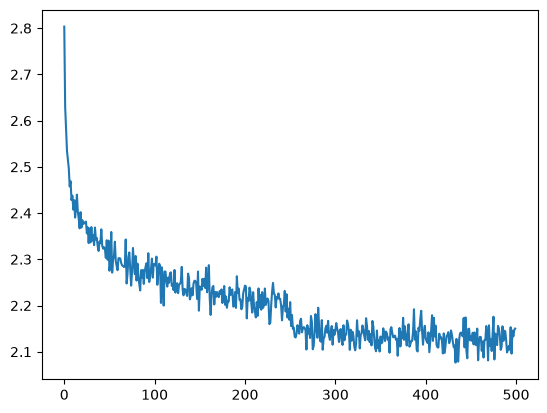

In [28]:
plt.plot(torch.tensor(lossi).view(-1, 100).mean(1))
plt.show()

In [29]:
g2 = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g2).item()
        context = context[1:] + [ix]
        if ix == 0:
            break
        out.append(itos[ix])
    print(''.join(out))

carlah
amelle
khi
mrisheaty
skanden
jazhitn
dellyn
jarquif
elmari
chaiivia
leigh
ham
joce
quinn
sulin
alianni
watthoniearisi
jaxeenitraylen
edo
abette


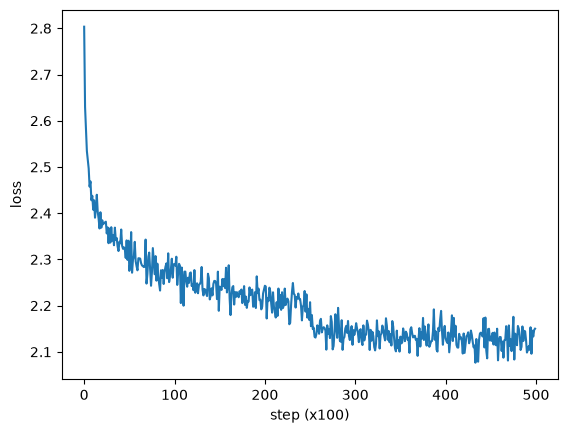

In [30]:
plt.plot(torch.tensor(lossi).view(-1, 100).mean(1))
plt.xlabel('step (x100)')
plt.ylabel('loss')
plt.savefig('loss_curve.png')
plt.show()

In [31]:
g2 = torch.Generator().manual_seed(2147483647 + 10)
names = []

for _ in range(50):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g2).item()
        context = context[1:] + [ix]
        if ix == 0:
            break
        out.append(itos[ix])
    names.append(''.join(out))

with open('samples.txt', 'w') as f:
    f.write('\n'.join(names))

print('train', split_loss(Xtr, Ytr))
print('dev', split_loss(Xdev, Ydev))
print('test', split_loss(Xte, Yte))

train 2.126598834991455
dev 2.152499198913574
test 2.150444746017456
